In [1]:
import shutil
from scipy.stats import qmc
import math
import re
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl

In [3]:
# default parameters (that we might change)
parameters = {}

parameters['D_ABC'] = [6.0e-10, 0.0, 6.0e-10]

parameters['seed'] = 43343
parameters['split_l'] = 30.0e-4
parameters['max_vol'] = 1e-12
parameters['max_l'] = 35.0e-4
parameters['max_r'] = 2.5e-4

parameters['k1'] = 2.0e-5
parameters['kr1'] = 2.0e-5
parameters['k2'] = 4.0
parameters['kr2'] = 0.0006
parameters['k3'] = 2.0e-5
parameters['kr3'] = 2.0e-5
parameters['k_g'] = 4.0
parameters['k_v'] = 40000.0
parameters['M_A'] = 2.0e-5
parameters['M_B'] = 2.0e-5
parameters['M_C'] = 2.0e-5

parameters['b_p'] = 0.0000
parameters['s_p'] = 0.2
parameters['f_p'] = 0.01
parameters['f_separation'] = 6.0e-4

parameters['eta'] = 1.0e6
parameters['zeta'] = 1.0e5
parameters['W_A'] = 1.0e-4
parameters['W_Z'] = 1.0e-4
parameters['f_bond'] = 1.0

In [12]:
# sampling
params = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
ranges = [[17.5, 52.5], [2.5, 7.5], [1.25, 3.75], [0.1, 0.3], [0.005, 0.015], [3.0, 9.0], [0.5, 1.5]]
to_change = dict(zip(params, ranges))
samples = {}
n_samples = 8 # must be power of 2

In [20]:
sampler = qmc.Sobol(d=len(params), scramble=True)
sample = sampler.random_base2(m=int(math.log2(n_samples)))
i = 0
for param in to_change.keys():
    if param == 'split_l':
        samples[param] = samples['max_l'] - (sample[:,i] * (to_change[param][1] - to_change[param][0]) + to_change[param][0])
    else:
        samples[param] = sample[:, i] * (to_change[param][1] - to_change[param][0]) + to_change[param][0]
    i += 1

In [4]:
# generate input files
for input_number in range(0,n_samples):
    file_name = 'input_fungi_' + str(input_number)
    shutil.copyfile('template_input_fungi', file_name)

    for param in params:
        parameters[param] = samples[param][input_number - 1]

    with open(file_name, 'a') as f:
        f.write('bmx.seed = ' + str(parameters['seed']) + '\nfluid.chem_species_diff = ' + str(parameters['D_ABC'][0]) + ' ' + str(parameters['D_ABC'][1]) + ' ' + str(parameters['D_ABC'][2]) + '\nchem_species.max_vol = ' + str(parameters['max_vol']) + '\nchem_species.seg_split_length = ' + str(round(parameters['split_l'], 2))  + 'e-4' + '\nchem_species.max_seg_length = '  + str(round(parameters['max_l'], 2)) + 'e-4' + '\nchem_species.max_seg_radius = ' + str(round(parameters['max_r'], 2)) + 'e-4' + '\nchem_species.k1 = ' + str(parameters['k1']) + '\nchem_species.kr1 = ' + str(parameters['kr1']) + '\nchem_species.k2 = ' + str(parameters['k2']) + '\nchem_species.kr2 = ' + str(parameters['kr2']) + '\nchem_species.k3 = ' + str(parameters['k3']) + '\nchem_species.kr3 = ' + str(parameters['kr3']) + '\nchem_species.kg = ' + str(parameters['k_g']) + '\nchem_species.kv = ' + str(parameters['k_v']) + '\nchem_species.mass_transfer_A = ' + str(parameters['M_A']) + '\nchem_species.mass_transfer_B = ' + str(parameters['M_B']) + '\nchem_species.mass_transfer_C = ' + str(parameters['M_C']) + '\nchem_species.branching_probability = ' + str(round(parameters['b_p'], 2)) + '\nchem_species.splitting_probability = ' + str(round(parameters['s_p'], 2)) + '\nchem_species.fusion_probability = ' + str(round(parameters['f_p'], 5)) + '\nchem_species.max_fusion_separation = ' + str(round(parameters['f_separation'], 2))  + 'e-4' + '\ncell_force.fungi_stiffness = ' + str(parameters['eta']) + '\ncell_force.fungi_wall_stiffness = ' + str(parameters['zeta']) + '\ncell_force.fungi_boundary_width = ' + str(round(parameters['W_A'], 2))  + 'e-4' + '\ncell_force.fungi_wall_boundary_width = ' + str(parameters['W_Z']) + '\ncell_force.bond_strength = ' + str(parameters['f_bond']))

In [5]:
# params = ['f_p']
# for input_number in range(0,n_samples):
#     file_name = 'input_fungi_' + str(input_number)

#     for param in params:
#         parameters[param] = samples[param][input_number - 1]

#     with open(file_name, 'a') as f:
#         f.write('\nchem_species.fusion_probability = ' + str(round(parameters['f_p'], 5)))

In [6]:
# for input_number in range(0,n_samples):
#     filename = 'input_fungi_' + str(input_number)
#     removed = False  # Flag to track if the first instance has been removed
    
#     with open(filename, 'r') as file:
#         lines = file.readlines()
    
#     with open(filename, 'w') as file:
#         for line in lines:
#             # Check if the line matches AND we haven't removed an instance yet
#             if line.startswith('chem_species.fusion_probability') and not removed:
#                 removed = True  # Set the flag to True to skip future matches
#                 continue  # Skip writing this line
#             file.write(line)

In [30]:
params = ['max_l(cm)', 'split_l(cm)', 'max_r(cm)', 's_p', 'f_p', 'f_separationcm)', 'W_A(cm)']
param_names = ['chem_species.max_seg_length = ', 'chem_species.seg_split_length = ',
               'chem_species.max_seg_radius = ', 'chem_species.splitting_probability = ',
               'chem_species.fusion_probability = ', 'chem_species.max_fusion_separation = ',
               'cell_force.fungi_boundary_width = '] 

In [31]:
run_params = {}
for n in range(256):
    input_filepath = '/Users/laurenyan/bmxfungi_surrogate/256_inputs/input_fungi_' + str(n)
    params_n = []
    for name in param_names:
        with open(input_filepath) as input_file:
            for line in input_file:
                if line.startswith(name):
                    params_n.append(re.findall(r"-?\d+\.?\d*(?:[Ee][+-]?\d+)?", line)[0])

        run_params[n] = params_n

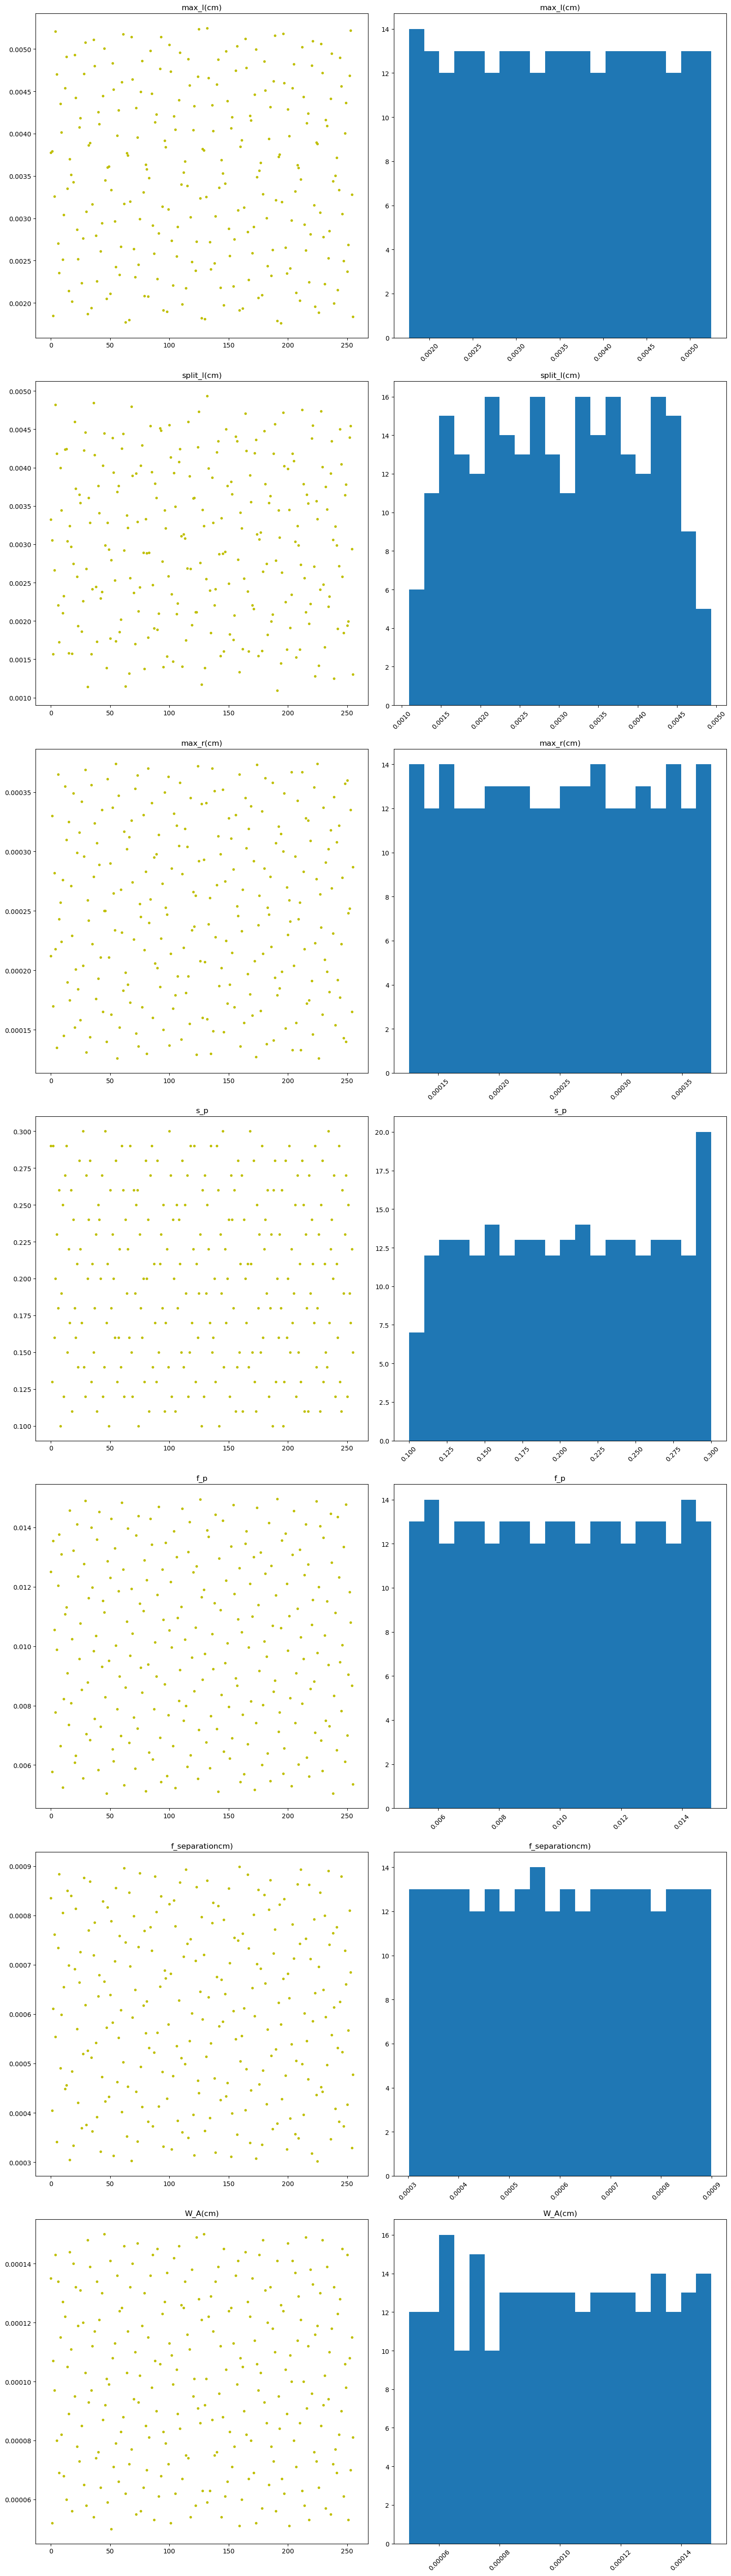

In [33]:
fig2, ax2 = plt.subplots(7, 2, figsize = (16, 56))
for par in np.arange(len(params)):
    hist_list = []
    for n in range(256):
        p = run_params[n]
        ax2[par,0].plot(n, float(p[par]), 'y.')
        hist_list.append(float(p[par]))
    ax2[par,1].hist(hist_list, bins = 20)
    ax2[par,0].set_title(params[par])
    ax2[par,1].set_title(params[par])
    for tick in ax2[par,1].get_xticklabels():
        tick.set_rotation(45)
plt.tight_layout()
plt.savefig('IBM_dist.png')